In [ ]:
import pandas as pd

import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



In [5]:
df=pd.read_csv("ecommerce_clean_data.csv")

In [6]:
df.head()

,orderid,orderdate,customerid,paymentmethod,orderstatus,customername,gender,age,city,region,...,profit,productname,category,costprice,sellingprice,year,month,monthname,yearmonth,profitmarginpct
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,12649.20,Mouse,Electronics,5353.0,10018.0,2026,1,January,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,6532.80,Shampoo,Beauty,3112.0,5568.0,2026,1,January,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3909.45,Table Lamp,Home,5905.0,10331.0,2026,2,February,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,2006.80,Air Fryer,Home,3425.0,4363.0,2026,2,February,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,4543.90,T-Shirt,Fashion,3999.0,6601.0,2025,11,November,2025-11,36.229758


In [7]:
df["orderdate"]=pd.to_datetime(df["orderdate"])

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12558 entries, 0 to 12557
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   orderid          12558 non-null  str           
 1   orderdate        12558 non-null  datetime64[us]
 2   customerid       12558 non-null  str           
 3   paymentmethod    12558 non-null  str           
 4   orderstatus      12558 non-null  str           
 5   customername     12558 non-null  str           
 6   gender           12558 non-null  str           
 7   age              12558 non-null  int64         
 8   city             12558 non-null  str           
 9   region           12558 non-null  str           
 10  signupdate       12558 non-null  str           
 11  orderdetailid    12558 non-null  str           
 12  productid        12558 non-null  str           
 13  quantity         12558 non-null  int64         
 14  unitprice        12558 non-null  float64       
 

In [13]:
target="profit"

In [14]:
#Features select

features=[
    "quantity",
    "unitprice",
    "discountpct",
    "category",
    "region",
    "paymentmethod"
]

In [15]:
X=df[features]
y=df[target]

In [16]:
X.isnull().sum()
y.isnull().sum()

np.int64(0)

In [17]:
X.dtypes

quantity           int64
unitprice        float64
discountpct      float64
category             str
region               str
paymentmethod        str
dtype: object

Train/test split

In [18]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [19]:
#Categorical columns


categorical_features=[
    "category",
    "region",
    "paymentmethod"
]

In [20]:
numerical_features=[
    "quantity",
    "unitprice",
    "discountpct"
]

In [21]:
#One hot encoding

preprocessor=ColumnTransformer (
    transformers=[
        (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore"
        ),
        categorical_features
        )
    ],
    remainder="passthrough"
)

In [22]:
#"Model"
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. 

In [23]:
model=RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [24]:
#Pipeline
pipeline=Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

In [25]:
#Train model
pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['quantity','unitprice','discountpct','category','region','paymentmethod']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenat

In [26]:
y_pred=pipeline.predict(X_test)

In [27]:
#Actual vs Predicted

comparison=pd.DataFrame({
    "ActualProfit": y_test.values,
    "PredictedProfit": y_pred
})
comparison.head(10)

,ActualProfit,PredictedProfit
0,3068.40,3066.84450
1,8642.00,9127.89900
2,502.35,495.53750
3,2876.35,2877.77975
4,1755.80,1754.39100
5,630.00,625.43550
6,-233.25,-172.32800
7,2379.80,2391.65000
8,2291.30,2300.45000
9,2184.00,2197.00000


In [28]:
#MAE
mae=mean_absolute_error(
    y_test,
    y_pred
)
mae

73.62323138933218

In [29]:
rmse=np.sqrt(
    mean_squared_error(
        y_test,y_pred
    )
)
rmse

np.float64(214.6089257402834)

In [30]:
#R sqaure
r2=r2_score(
    y_test,
    y_pred
)
r2

0.997924839899611

In [31]:
print("MAE: ",mae)
print("RMSE: ",rmse)
print("R2: ",r2)

MAE:  73.62323138933218
RMSE:  214.6089257402834
R2:  0.997924839899611


Text(0.5, 1.0, 'Actual vs Predicted Profit')

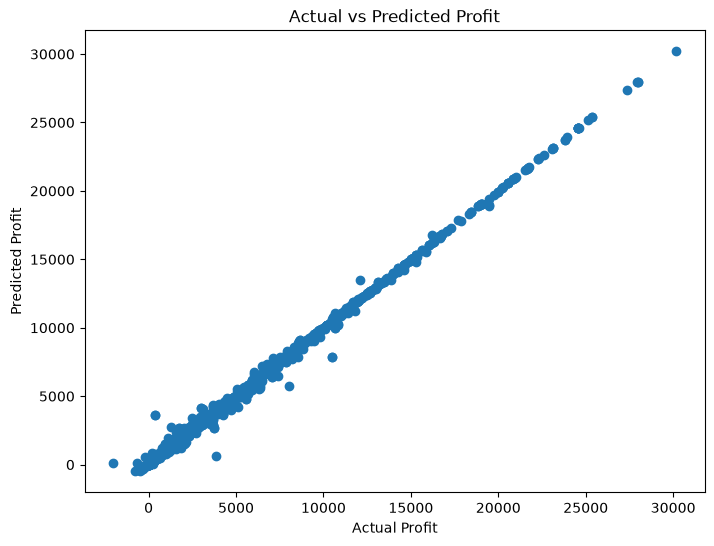

In [34]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(
    y_test,
    y_pred
)
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Actual vs Predicted Profit")

In [35]:
#Residuals

residuals=y_test-y_pred
residuals.describe()

count    2.512000e+03
mean    -1.649565e-01
std      2.146516e+02
min     -3.233608e+03
25%     -1.513206e+01
50%     -7.531753e-13
75%      1.342288e+01
max      3.247611e+03
Name: profit, dtype: float64

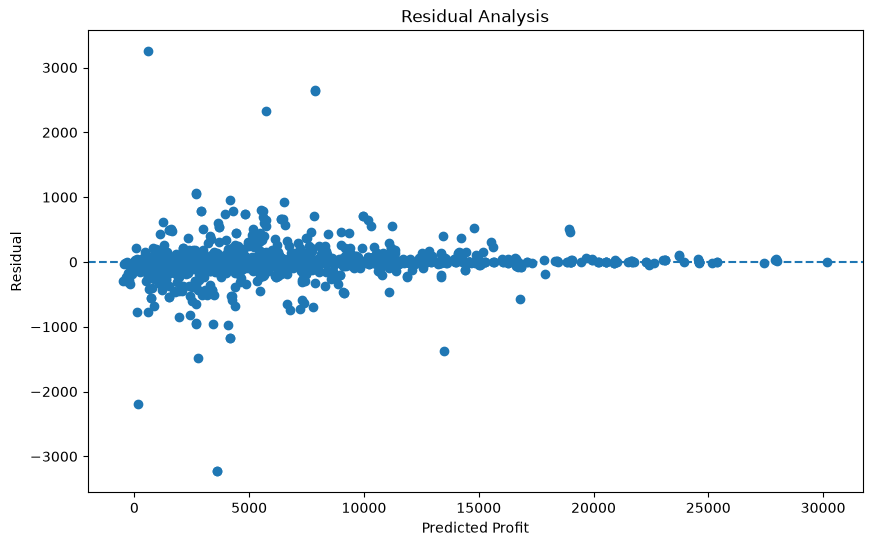

In [36]:
plt.figure(figsize=(10,6))
plt.scatter(
    y_pred,
    residuals
)
plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Profit")
plt.ylabel("Residual")
plt.title("Residual Analysis")

plt.show()